In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("../data/flood_clean.csv", parse_dates=["timestamp"])
df = df.sort_values(["station_id", "timestamp"]).reset_index(drop=True)

# CSV padhte waqt pandas "None" ko khaali (NaN) samajh leta hai, isliye dobara bharo
df["flood_severity"] = df["flood_severity"].fillna("None")

print("Shape:", df.shape)

Shape: (87720, 20)


In [2]:
df["month"] = df["timestamp"].dt.month
df["hour"] = df["timestamp"].dt.hour

df["month_sin"] = np.sin(2 * np.pi * df["month"] / 12)
df["month_cos"] = np.cos(2 * np.pi * df["month"] / 12)
df["hour_sin"] = np.sin(2 * np.pi * df["hour"] / 24)
df["hour_cos"] = np.cos(2 * np.pi * df["hour"] / 24)

df["is_monsoon"] = df["month"].between(5, 9).astype(int)

In [3]:
df["wind_sin"] = np.sin(np.radians(df["wind_direction_deg"]))
df["wind_cos"] = np.cos(np.radians(df["wind_direction_deg"]))

In [4]:
df["wind_sin"] = np.sin(np.radians(df["wind_direction_deg"]))
df["wind_cos"] = np.cos(np.radians(df["wind_direction_deg"]))

In [5]:
df["level_gap"] = df["water_level_m"] - df["danger_level_m"]
print(df.groupby("station_id")["level_gap"].agg(["min", "max"]))

             min   max
station_id            
ASM_DB02   -1.97  7.71
ASM_GW01   -1.24  9.14
ASM_JR05   -1.60  8.55
ASM_SL03   -1.69  8.18
ASM_TZ04   -1.19  7.79


In [6]:
upstream_of = {"ASM_JR05": "ASM_DB02",    # Jorhat   <- Dibrugarh
               "ASM_TZ04": "ASM_JR05",    # Tezpur   <- Jorhat
               "ASM_GW01": "ASM_TZ04"}    # Guwahati <- Tezpur

df["upstream_station"] = df["station_id"].map(upstream_of)
up = df[["timestamp", "station_id", "level_gap"]].rename(
    columns={"station_id": "upstream_station", "level_gap": "upstream_gap"})

df = df.merge(up, on=["timestamp", "upstream_station"], how="left")
df["upstream_gap"] = df["upstream_gap"].fillna(0)
df["has_upstream"] = df["upstream_station"].notna().astype(int)
df = df.drop(columns=["upstream_station"])

df = df.sort_values(["station_id", "timestamp"]).reset_index(drop=True)

In [7]:
station = df.groupby("station_id")

for h in [1, 3, 6, 12, 24, 48]:
    df[f"level_lag_{h}h"] = station["level_gap"].shift(h)
    df[f"level_rise_{h}h"] = df["level_gap"] - df[f"level_lag_{h}h"]

df["upstream_rise_24h"] = df["upstream_gap"] - station["upstream_gap"].shift(24)

In [8]:
for w in [3, 6, 12, 24, 48, 72, 168]:
    df[f"rain_sum_{w}h"] = station["rainfall_mm"].transform(lambda x: x.rolling(w, min_periods=1).sum())
    df[f"satrain_sum_{w}h"] = station["satellite_rainfall_mm"].transform(lambda x: x.rolling(w, min_periods=1).sum())

df["rain_max_24h"] = station["rainfall_mm"].transform(lambda x: x.rolling(24, min_periods=1).max())

In [9]:
df["humidity_mean_24h"] = station["humidity_pct"].transform(lambda x: x.rolling(24, min_periods=1).mean())
df["pressure_change_24h"] = df["pressure_hpa"] - station["pressure_hpa"].shift(24)

In [10]:
rain_cols = [c for c in df.columns if c.startswith(("rain", "satrain", "satellite_rain"))]
for col in rain_cols:
    df[col] = np.log1p(df[col])

print("Log transform applied on", len(rain_cols), "columns")

Log transform applied on 17 columns


In [11]:
for h in [6, 24, 72]:
    future = pd.concat([station["flood_occurred"].shift(-i) for i in range(1, h + 1)], axis=1)
    df[f"flood_next_{h}h"] = future.max(axis=1, skipna=False)
    df[f"onset_next_{h}h"] = ((df["flood_occurred"] == 0) & (df[f"flood_next_{h}h"] == 1)).astype(int)

In [12]:
df = pd.concat([df, pd.get_dummies(df["station_id"], prefix="stn", dtype=int)], axis=1)

In [13]:
start = df.groupby("station_id")["timestamp"].transform("min")
df = df[df["timestamp"] >= start + pd.Timedelta(days=7)]
df = df.dropna(subset=["flood_next_72h"]).reset_index(drop=True)

print("Final shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())

Final shape: (86520, 73)
Missing values: 0


In [14]:
targets = [c for c in df.columns if c.startswith(("flood_next", "onset_next"))]

drop_cols = ["timestamp", "station_id", "station_name", "district", "river",
             "latitude", "longitude", "month", "hour", "wind_direction_deg",
             "water_level_m", "danger_level_m",
             "flood_occurred", "flood_severity", "flood_extent_km2"]

features = [c for c in df.columns if c not in drop_cols + targets]

print("Total features:", len(features))
print("flood_next_24h %:", round(df["flood_next_24h"].mean() * 100, 2))
print("onset_next_24h %:", round(df["onset_next_24h"].mean() * 100, 2))

Total features: 52
flood_next_24h %: 29.35
onset_next_24h %: 1.7


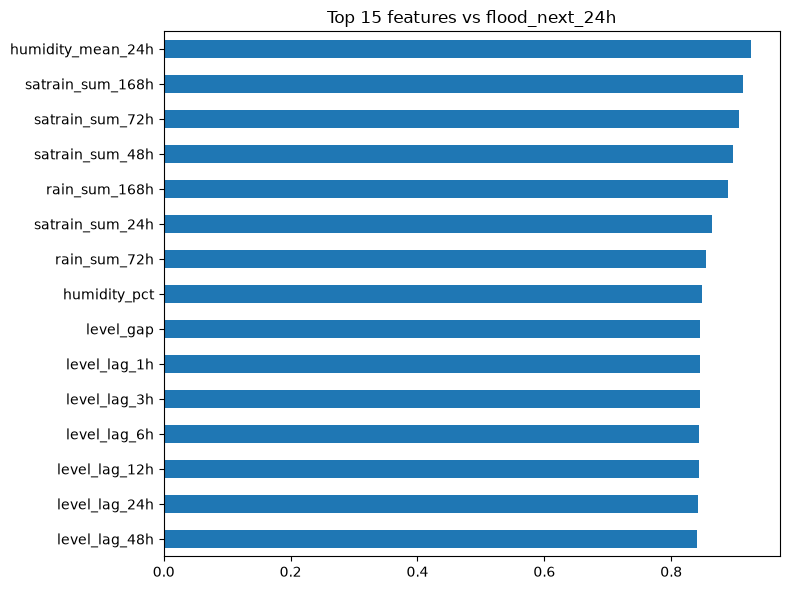

In [15]:
corr = df[features + ["flood_next_24h"]].corr()["flood_next_24h"].drop("flood_next_24h")
top = corr.abs().sort_values(ascending=False).head(15)

top.sort_values().plot(kind="barh", figsize=(8, 6), title="Top 15 features vs flood_next_24h")
plt.tight_layout()
plt.show()

In [16]:
df.to_csv("../data/flood_features.csv", index=False)
print("Saved! Shape:", df.shape)

Saved! Shape: (86520, 73)
